# Estimer les paramètres pharmacocinétiques de la théophylline

Ce notebook présente les résultats du projet. Le calcul est dans le package `pkopt` (`src/pkopt/`)
et dans les scripts de `scripts/`, qui écrivent les tableaux dans `resultats/` et les figures dans `figures/`.

Le modèle est à un compartiment, avec absorption d'ordre 1 :

$$U(t) = \frac{D\,k_a}{V\,(k_a - k_e)}\left(e^{-k_e t} - e^{-k_a t}\right)$$

On cherche $\theta = (k_a, k_e, V)$ qui minimise $J(\theta) = \sum_i \big(U(t_i;\theta) - y_i\big)^2$.

In [1]:
import csv

import numpy as np
from IPython.display import Image, Markdown, display

from pkopt import deterministes, donnees, modele, objectif, strategie
from pkopt.donnees import RACINE

FIG, RES = RACINE / "figures", RACINE / "resultats"
np.set_printoptions(precision=4, suppress=True)

Les données : les 12 patients réels, 12 patients synthétiques dont on connaît les vrais paramètres,
et ces mêmes patients bruités à 5, 10 et 25 %.

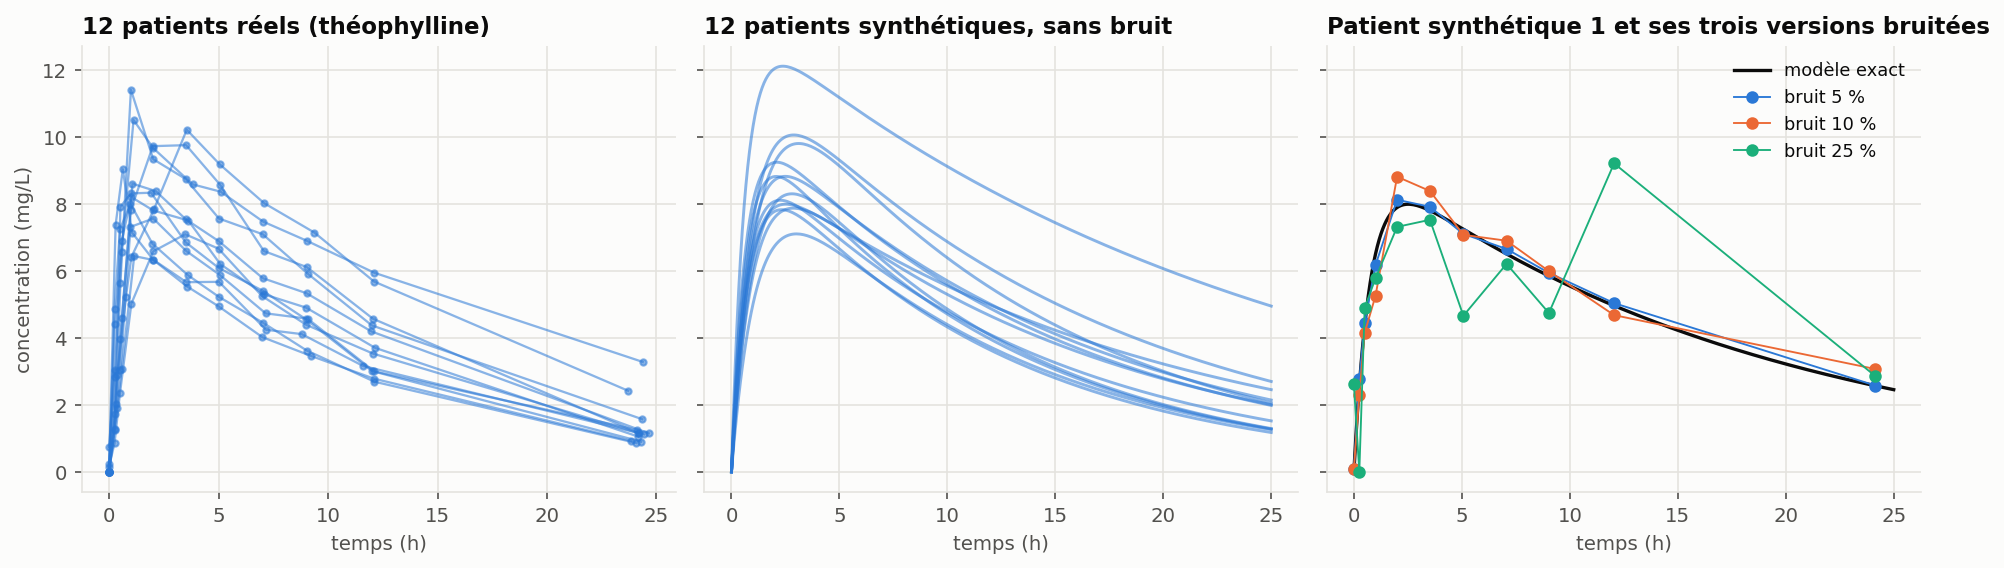

In [2]:
display(Image(FIG / "08_donnees.png", width=900))

## 1. Le critère a deux minima globaux

Le modèle ne change pas si l'on échange $k_a$ et $k_e$ en remplaçant $V$ par $V\,k_e/k_a$
(phénomène de *flip-flop*). Le critère a donc toujours deux minima de même valeur, et c'est
la seule vraie source de non-convexité. On garde la solution $k_a > k_e$, la plus plausible pour
un comprimé avalé : c'est l'absorption qui est rapide.

In [3]:
patients = donnees.charger_theophylline()
p = patients[0]
theta = strategie.estimer(p).x
miroir = np.array([theta[1], theta[0], theta[2] * theta[1] / theta[0]])
print("solution retenue :", theta, " J =", round(objectif.critere(theta, p), 6))
print("solution miroir  :", miroir, " J =", round(objectif.critere(miroir, p), 6))

solution retenue : [ 1.7774  0.054  27.557 ]  J = 4.286009
solution miroir  : [0.054  1.7774 0.8365]  J = 4.286009


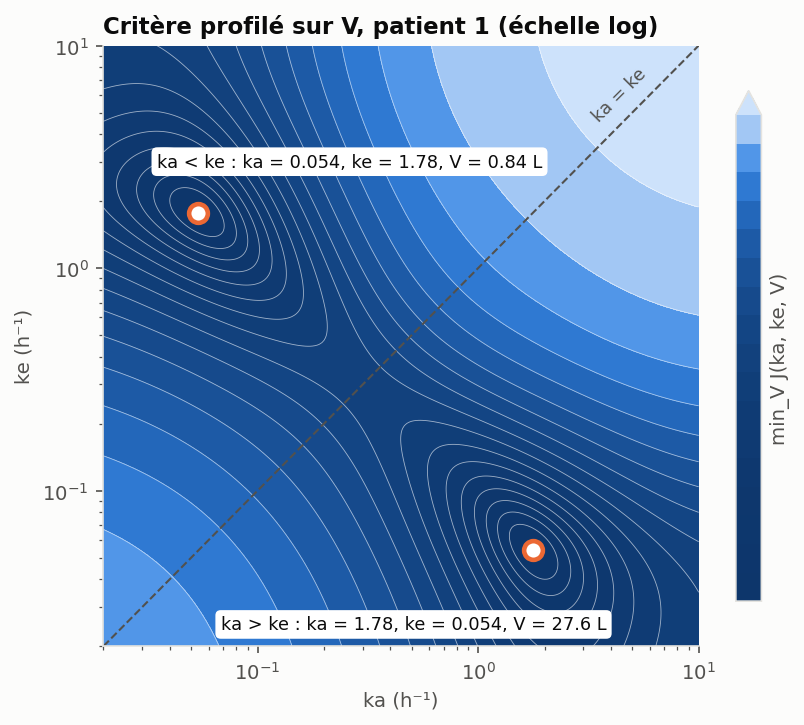

In [4]:
display(Image(FIG / "01_paysage_flip_flop.png", width=560))

## 2. Pourquoi la descente de gradient échouait

Dans la première version du projet, le gradient à pas optimal restait loin de la solution, et on
y voyait un minimum local. En réalité, c'est un problème de **conditionnement** : $k_e \approx 0.1$ et
$V \approx 30$ n'ont pas la même échelle, et la hessienne a un conditionnement de l'ordre de $10^5$.
Le même algorithme, appliqué à $\log\theta$, converge.

In [5]:
theta_vrai = donnees.patients_synthetiques()[0]
q = donnees.bruiter(theta_vrai, 0.10, np.random.default_rng(0))
x0 = donnees.patients_synthetiques().mean(axis=0)

f, g, h = objectif.probleme(q)
fl, gl, hl = objectif.probleme(q, log=True)
nat = deterministes.descente_gradient(f, g, x0, max_iter=300)
log = deterministes.descente_gradient(fl, gl, np.log(x0), max_iter=300)
newton = deterministes.newton(fl, gl, hl, np.log(x0))

print(f"vrai θ                 : {theta_vrai}")
print(f"gradient en θ          : {nat.x}   J = {nat.f:.4f}")
print(f"gradient en log θ      : {np.exp(log.x)}   J = {log.f:.4f}")
print(f"Newton en log θ        : {np.exp(newton.x)}   J = {newton.f:.4f}  ({newton.n_eval} évaluations)")
print(f"conditionnement de H   : {np.linalg.cond(h(np.exp(newton.x))):.2e} en θ, "
      f"{np.linalg.cond(hl(newton.x)):.0f} en log θ")

vrai θ                 : [ 1.3219  0.0544 32.7523]
gradient en θ          : [ 1.0894  0.0723 29.1817]   J = 1.2688
gradient en log θ      : [ 1.1906  0.0657 30.5878]   J = 1.1158
Newton en log θ        : [ 1.1906  0.0657 30.5878]   J = 1.1158  (16 évaluations)
conditionnement de H   : 1.39e+05 en θ, 58 en log θ


En θ, la composante du gradient sur $V$ est environ 70 fois plus faible que celle sur $k_e$ :
$V$ ne bouge presque pas, et $k_e$ oscille d'une itération à l'autre.

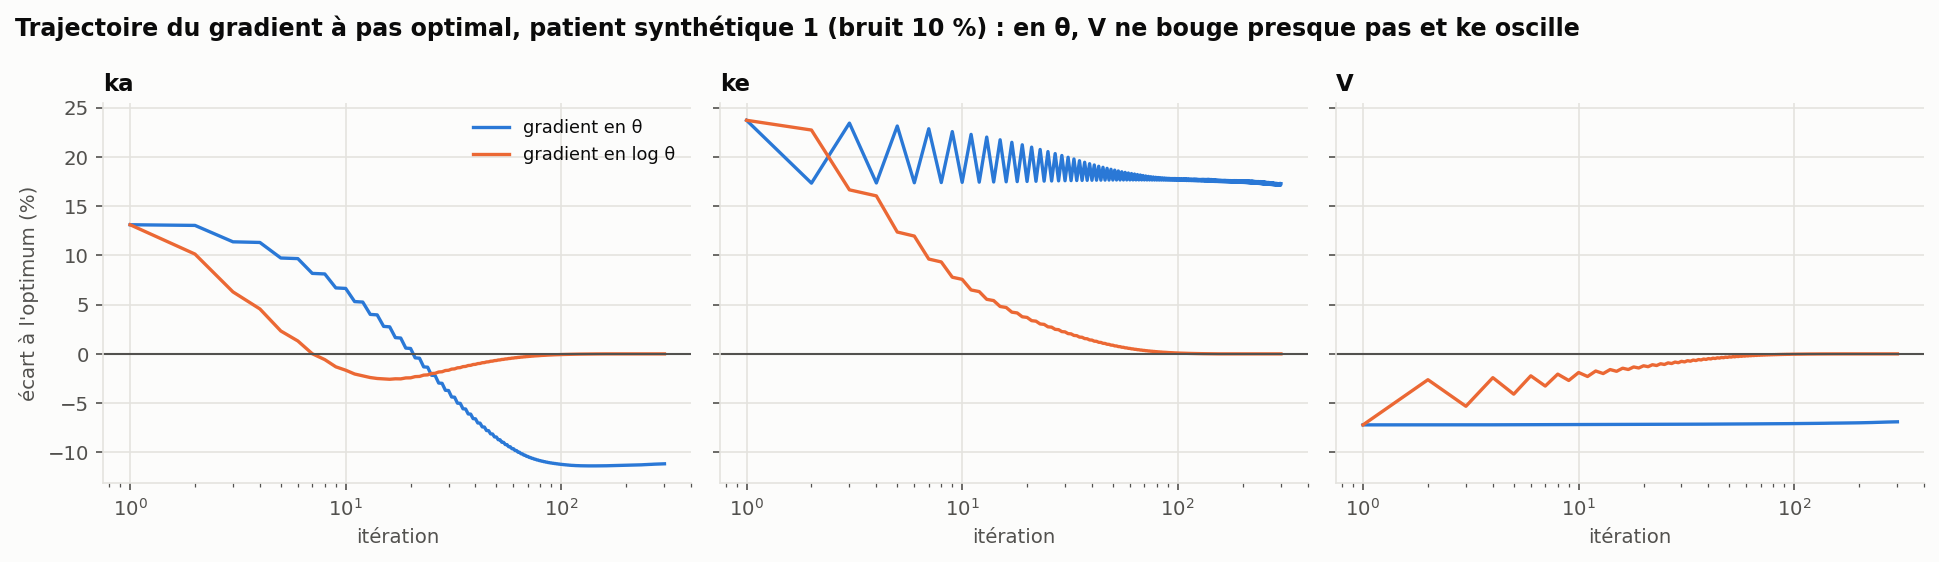

In [6]:
display(Image(FIG / "09_trajectoires_gradient.png", width=900))

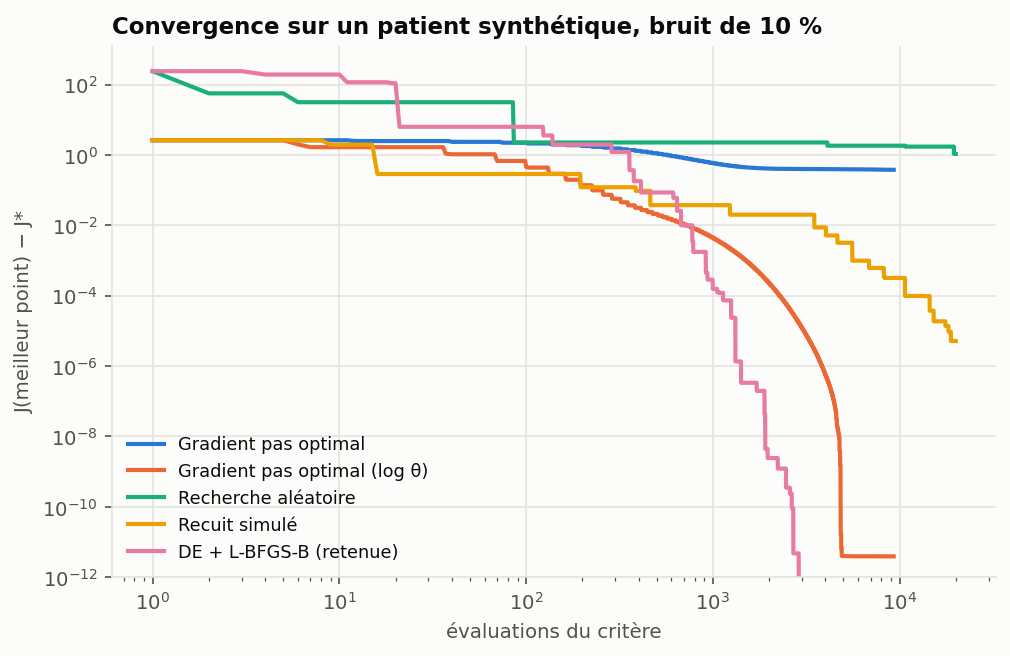

In [7]:
display(Image(FIG / "03_convergence.png", width=640))

Le changement de variable rend aussi les méthodes locales insensibles au point de départ
(100 départs tirés au hasard sur 4 patients).

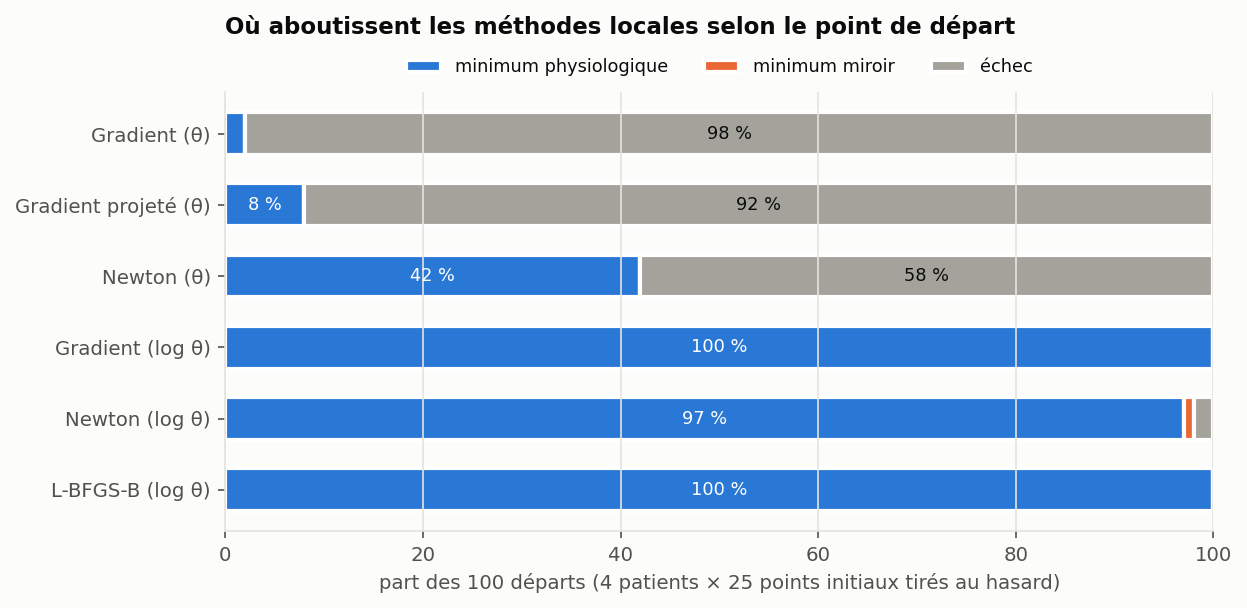

In [8]:
display(Image(FIG / "10_points_initiaux.png", width=640))

## 3. Comparaison des méthodes

Douze méthodes sur 120 jeux de données synthétiques (12 patients, 4 niveaux de bruit, 3 tirages du bruit).
On sépare deux questions que la première version mélangeait :

- **la méthode trouve-t-elle le minimum global ?** C'est le taux de réussite ci-dessous ;
- **ce minimum est-il proche des vrais paramètres ?** Cela ne dépend plus de l'optimiseur, seulement du bruit.

In [9]:
display(Markdown((RES / "benchmark_resume.md").read_text(encoding="utf-8").split("\n", 2)[2]))

Réussite : part des jeux de données où chaque paramètre est à 1 % près du meilleur point trouvé toutes méthodes confondues.

| Méthode | Réussite sans bruit | Réussite 5 % | Réussite 10 % | Réussite 25 % | Évaluations (médiane) |
|---|---|---|---|---|---|
| Gradient pas optimal | 0 % | 25 % | 17 % | 17 % | 9 602 |
| Gradient projeté | 0 % | 19 % | 25 % | 22 % | 9 602 |
| Gradient pas optimal (log θ) | 100 % | 100 % | 100 % | 100 % | 9 602 |
| Newton | 92 % | 100 % | 94 % | 92 % | 24 |
| Newton projeté (log θ) | 100 % | 100 % | 100 % | 100 % | 20 |
| L-BFGS-B (log θ) | 100 % | 100 % | 100 % | 100 % | 39 |
| Recherche aléatoire | 0 % | 0 % | 0 % | 0 % | 20 000 |
| Recherche localisée | 100 % | 100 % | 100 % | 100 % | 20 000 |
| Metropolis | 100 % | 100 % | 94 % | 92 % | 20 000 |
| Recuit simulé | 100 % | 100 % | 94 % | 97 % | 20 000 |
| Évolution différentielle | 100 % | 97 % | 94 % | 94 % | 3 150 |
| DE + L-BFGS-B (retenue) | 100 % | 100 % | 100 % | 100 % | 3 212 |

## Erreur relative de la méthode retenue par rapport aux vrais paramètres

| Bruit | ka | ke | V |
|---|---|---|---|
| 5 % | 5.3 % (90 % des cas < 10 %) | 5.0 % (90 % des cas < 9 %) | 1.5 % (90 % des cas < 5 %) |
| 10 % | 7.5 % (90 % des cas < 27 %) | 6.1 % (90 % des cas < 17 %) | 3.1 % (90 % des cas < 10 %) |
| 25 % | 19.9 % (90 % des cas < 48 %) | 22.1 % (90 % des cas < 49 %) | 11.2 % (90 % des cas < 20 %) |


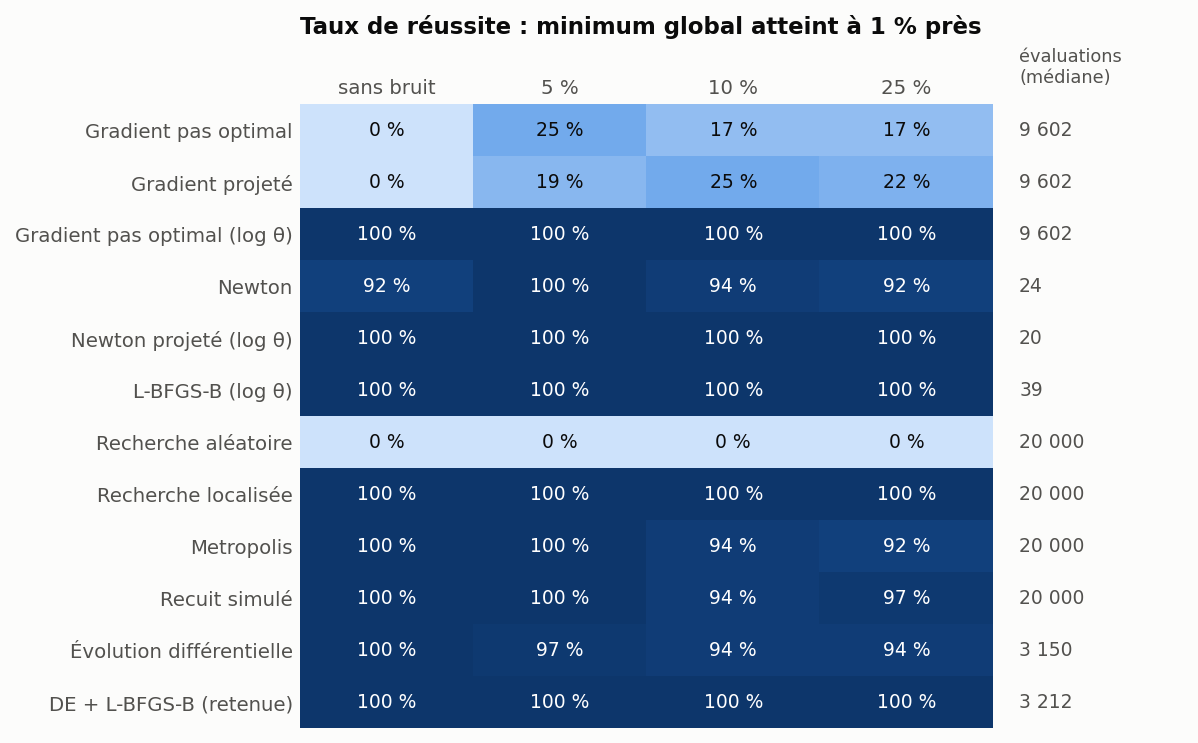

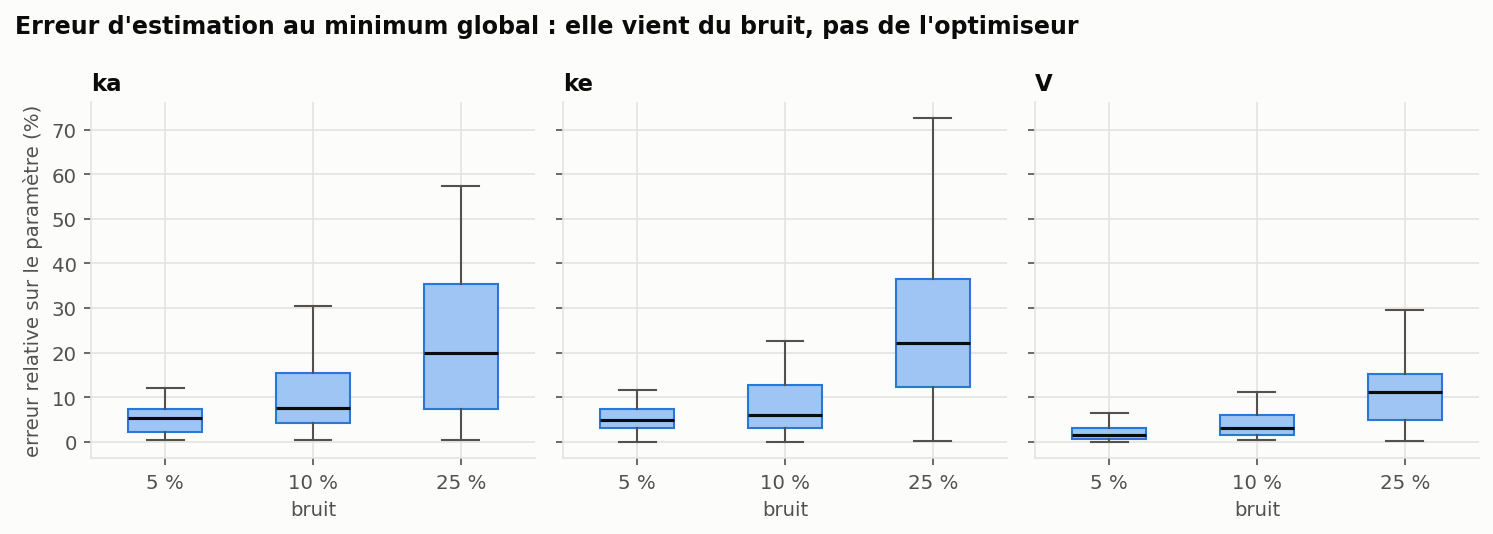

In [10]:
display(Image(FIG / "02_taux_de_reussite.png", width=640))
display(Image(FIG / "04_erreur_estimation.png", width=760))

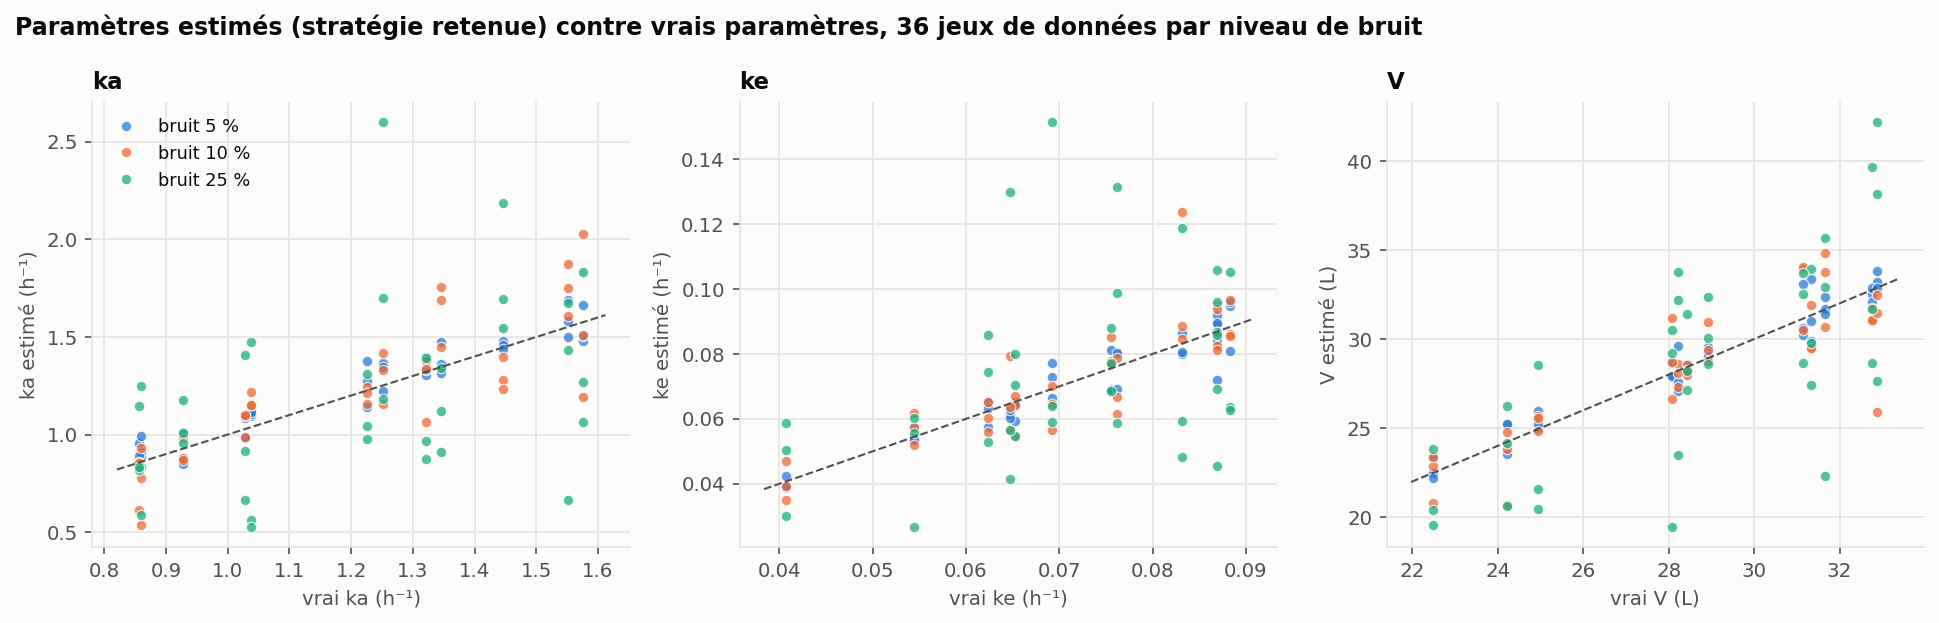

In [11]:
display(Image(FIG / "12_estime_vs_vrai.png", width=900))

**Réglages des méthodes stochastiques.** Le recuit simulé atteint le minimum quelle que soit sa
température initiale : une fois la solution miroir exclue par les bornes, le paysage n'a qu'une vallée, et le
recuit se comporte comme une recherche locale. La recherche aléatoire reste à environ 3 % du minimum même avec
un million d'évaluations.

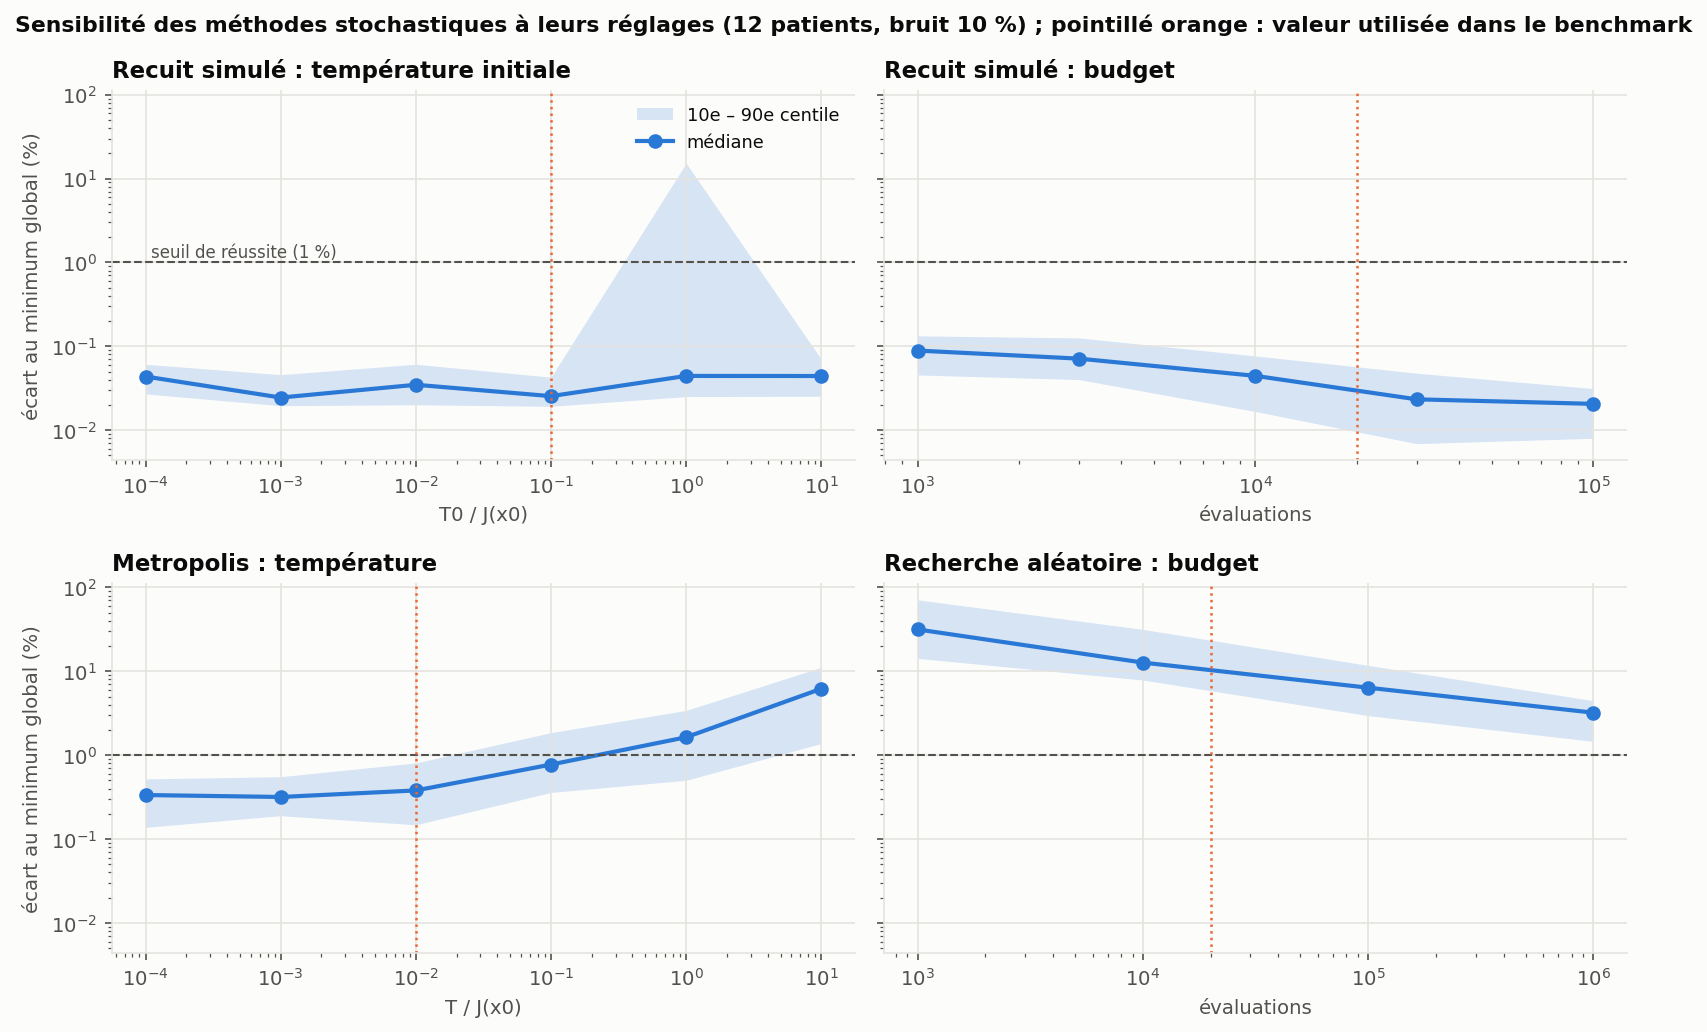

In [12]:
display(Image(FIG / "11_hyperparametres.png", width=820))

## 4. Les 12 patients réels

Pour chaque patient : l'estimation, un intervalle de confiance à 95 % obtenu par linéarisation
(calculé en $\log\theta$) et 1 000 réestimations bootstrap des résidus.

In [13]:
lignes = list(csv.DictReader(open(RES / "donnees_reelles.csv", encoding="utf-8")))
tab = ["| Patient | ka (h⁻¹) | ke (h⁻¹) | V (L) | t½ (h) | R² |", "|---|---|---|---|---|---|"]
for l in lignes:
    f_ = lambda n, d: f"{float(l[n]):.{d}f} [{float(l[n + '_ic_bas']):.{d}f} ; {float(l[n + '_ic_haut']):.{d}f}]"
    tab.append(f"| {l['patient']} | {f_('ka', 2)} | {f_('ke', 3)} | {f_('V', 1)} | "
               f"{float(l['demi_vie_h']):.1f} | {float(l['R2']):.3f} |")
display(Markdown("\n".join(tab)))

| Patient | ka (h⁻¹) | ke (h⁻¹) | V (L) | t½ (h) | R² |
|---|---|---|---|---|---|
| 1 | 1.78 [1.19 ; 2.65] | 0.054 [0.036 ; 0.080] | 27.6 [24.0 ; 31.7] | 12.8 | 0.953 |
| 2 | 1.94 [0.98 ; 3.85] | 0.102 [0.057 ; 0.181] | 30.0 [22.8 ; 39.5] | 6.8 | 0.902 |
| 3 | 2.45 [2.09 ; 2.88] | 0.081 [0.072 ; 0.093] | 32.2 [30.5 ; 34.0] | 8.5 | 0.994 |
| 4 | 1.17 [0.69 ; 1.99] | 0.087 [0.052 ; 0.147] | 29.2 [22.9 ; 37.1] | 7.9 | 0.933 |
| 5 | 1.47 [0.74 ; 2.91] | 0.088 [0.047 ; 0.168] | 25.2 [18.8 ; 33.9] | 7.8 | 0.892 |
| 6 | 1.16 [0.71 ; 1.91] | 0.100 [0.063 ; 0.156] | 38.5 [30.7 ; 48.3] | 7.0 | 0.949 |
| 7 | 0.68 [0.50 ; 0.92] | 0.102 [0.075 ; 0.139] | 30.6 [25.8 ; 36.2] | 6.8 | 0.984 |
| 8 | 1.38 [0.84 ; 2.24] | 0.092 [0.059 ; 0.145] | 33.5 [27.0 ; 41.5] | 7.5 | 0.939 |
| 9 | 8.87 [3.22 ; 24.39] | 0.087 [0.065 ; 0.116] | 36.5 [32.8 ; 40.6] | 8.0 | 0.966 |
| 10 | 0.70 [0.55 ; 0.87] | 0.074 [0.058 ; 0.095] | 23.9 [21.3 ; 26.9] | 9.4 | 0.985 |
| 11 | 3.85 [3.19 ; 4.64] | 0.098 [0.086 ; 0.111] | 35.6 [33.6 ; 37.6] | 7.1 | 0.993 |
| 12 | 0.83 [0.59 ; 1.18] | 0.106 [0.075 ; 0.148] | 22.5 [18.7 ; 27.0] | 6.6 | 0.977 |

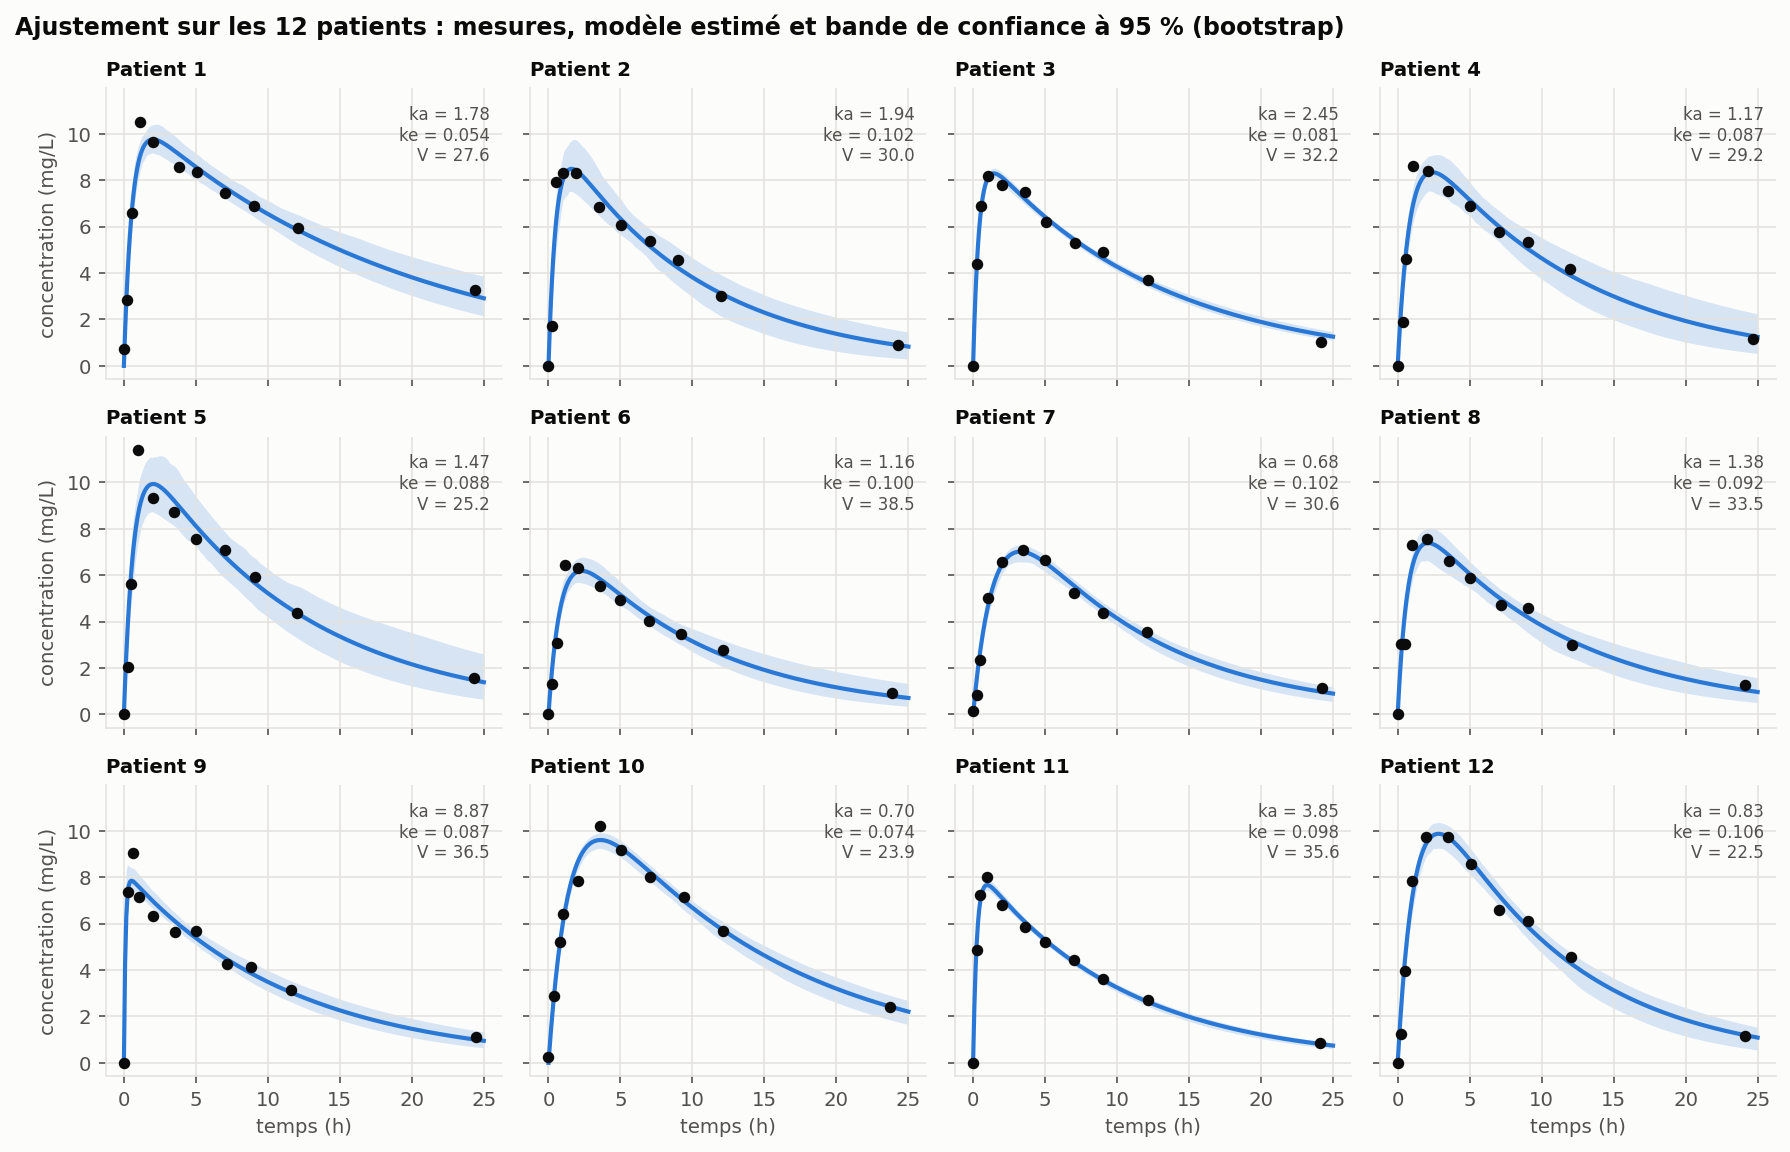

In [14]:
display(Image(FIG / "05_ajustements_patients.png", width=900))

Le patient 9 atteint son pic avant le deuxième prélèvement (0,3 h). Les données disent seulement
que l'absorption est rapide : $k_a$ n'a pas de borne supérieure crédible, comme le montre le nuage
bootstrap qui s'étale jusqu'à la borne $k_a = 20$. Son volume $V$ reste pourtant déterminé à ±11 % près.

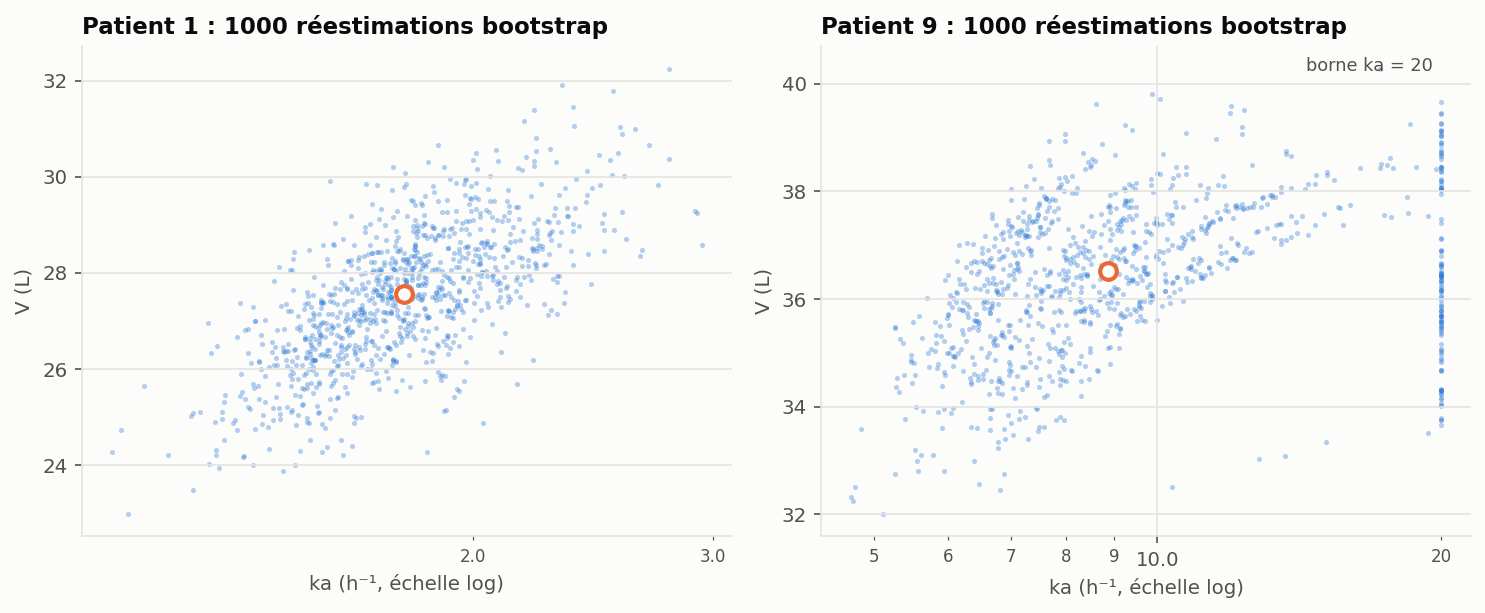

In [15]:
display(Image(FIG / "06_identifiabilite_ka.png", width=760))

**Résidus.** Leur écart quadratique moyen vaut 0,93 mg/L pendant l'absorption (0 à 2,5 h), contre
0,26 mg/L ensuite. L'absorption d'ordre 1 sans temps de latence décrit mal les premières heures.

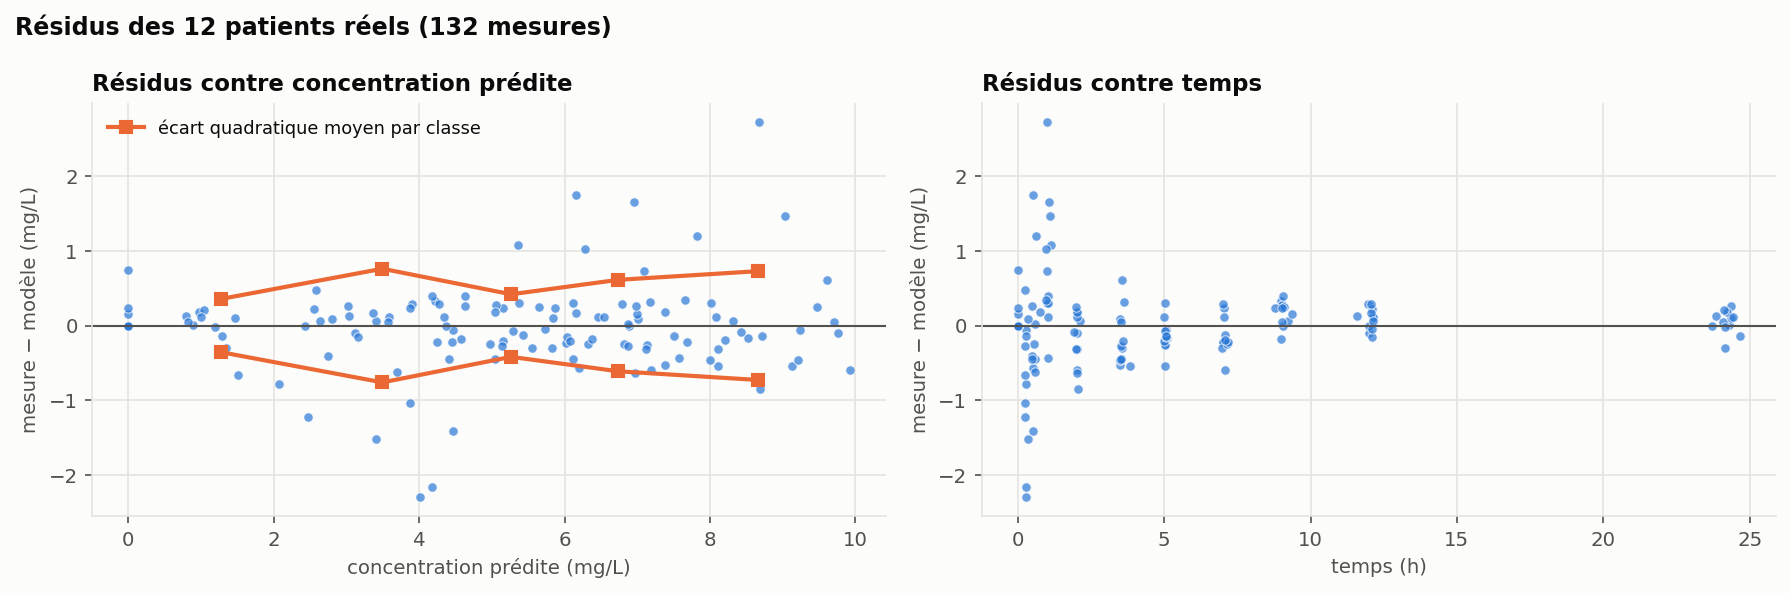

In [16]:
display(Image(FIG / "13_residus.png", width=860))

## 5. Second cas d'étude : les données synthétiques de l'annexe

Ces 12 patients sont simulés puis bruités, et leurs vrais paramètres ne sont pas connus.
La même stratégie s'applique sans changement.

| Patient | ka (h⁻¹) | ke (h⁻¹) | V (L) | R² |
|---|---|---|---|---|
| 1 | 1.273 | 0.1324 | 24.32 | 0.992 |
| 2 | 1.586 | 0.1280 | 22.66 | 0.995 |
| 3 | 0.905 | 0.1105 | 23.70 | 0.999 |
| 4 | 2.036 | 0.1009 | 25.12 | 0.998 |
| 5 | 1.000 | 0.1003 | 31.46 | 0.996 |
| 6 | 1.027 | 0.0956 | 33.30 | 0.995 |
| 7 | 1.581 | 0.1294 | 31.82 | 0.995 |
| 8 | 2.085 | 0.0947 | 30.13 | 0.986 |
| 9 | 0.866 | 0.0741 | 37.76 | 0.990 |
| 10 | 1.570 | 0.0805 | 24.69 | 0.993 |
| 11 | 1.546 | 0.0961 | 31.70 | 0.988 |
| 12 | 1.252 | 0.1021 | 31.91 | 0.994 |

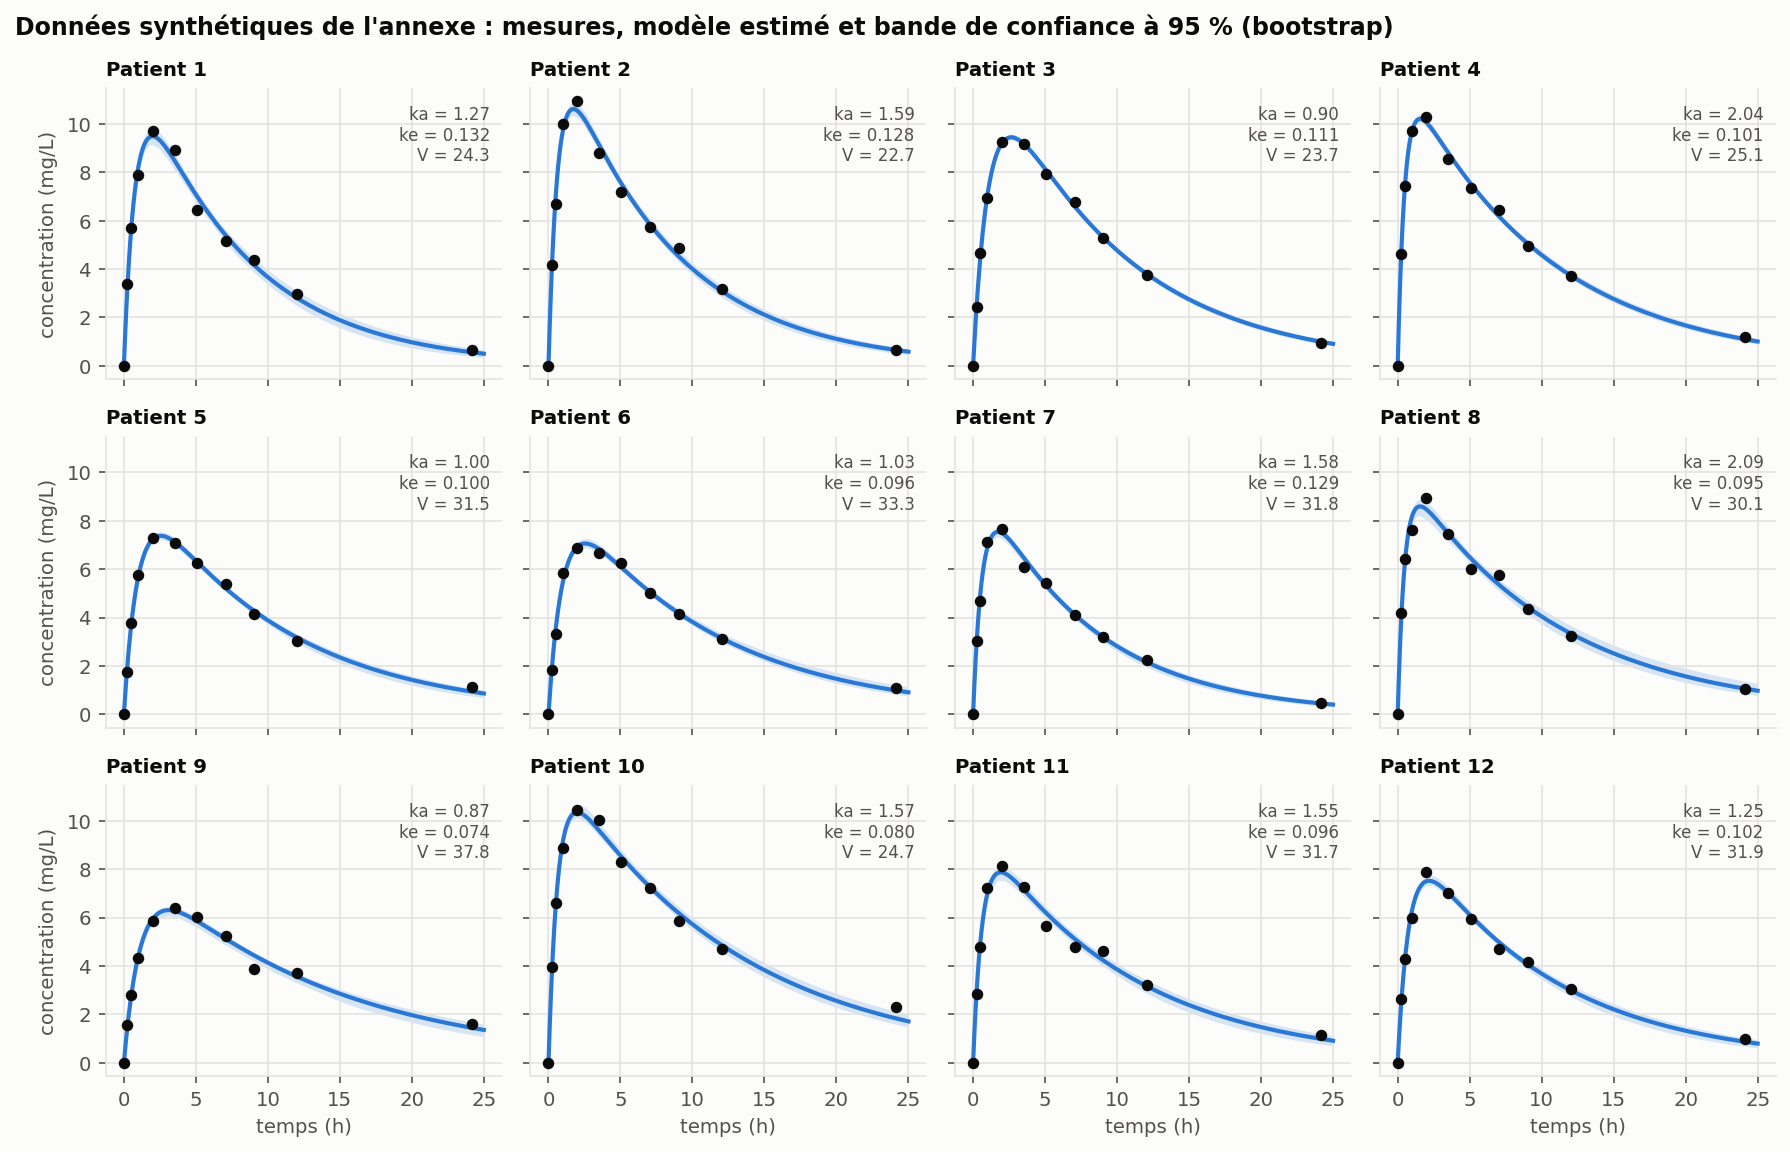

In [17]:
annexe = list(csv.DictReader(open(RES / "donnees_annexe.csv", encoding="utf-8")))
tab = ["| Patient | ka (h⁻¹) | ke (h⁻¹) | V (L) | R² |", "|---|---|---|---|---|"]
for l in annexe:
    tab.append(f"| {l['patient']} | {float(l['ka']):.3f} | {float(l['ke']):.4f} | "
               f"{float(l['V']):.2f} | {float(l['R2']):.3f} |")
display(Markdown("\n".join(tab)))
display(Image(FIG / "07_ajustements_annexe.png", width=900))

## 6. Limites et suites possibles

- L'énoncé fixe la dose à 300 mg pour tous ; les vraies doses vont de 268 à 321 mg. Cela ne change que $V$
  (proportionnellement à la dose), pas $k_a$ ni $k_e$.
- L'absorption démarre dès la prise dans ce modèle ; les résidus suggèrent d'ajouter un temps de latence.
- Le bruit est supposé additif et de variance constante ; en pharmacocinétique, une erreur proportionnelle
  à la concentration est souvent plus réaliste (moindres carrés pondérés).
- Chaque patient est estimé seul. Un modèle à effets mixtes (approche de population) partagerait
  l'information entre patients et stabiliserait les cas comme le patient 9.